# Lab 8: Hierarchical clustering and DBSCAN

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

X = [2, 8, 0, 7, 6]
Y = [0, 4, 6, 2, 1]
labels = ["x1", "x2", "x3", "x4", "x5"]
hdata = pd.DataFrame({"X": X, "Y": Y}, index=labels)

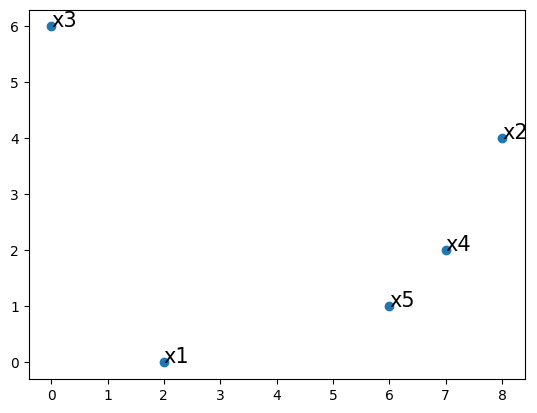

In [2]:
plt.scatter(hdata.X, hdata.Y)
for i in range(len(hdata.index)):
    plt.text(hdata.loc[labels[i], "X"], hdata.loc[labels[i], "Y"], '%s' % (str(labels[i])), size=15, zorder=1) 
plt.show()

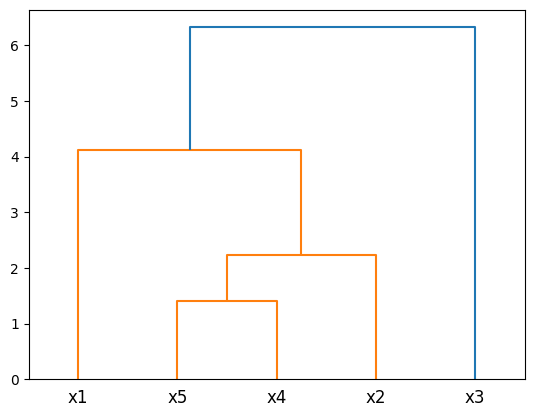

In [3]:
clustering = AgglomerativeClustering(n_clusters=None, linkage="single", distance_threshold=0).fit(hdata)
linkage_matrix = np.column_stack([clustering.children_, clustering.distances_, np.ones(len(hdata.index)-1)]).astype(float)
dendrogram(linkage_matrix, labels=labels)
plt.show()

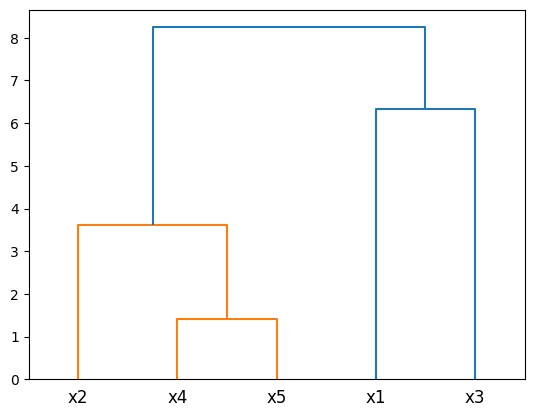

In [4]:
clustering = AgglomerativeClustering(n_clusters=None, linkage="complete", distance_threshold=0).fit(hdata)
linkage_matrix = np.column_stack([clustering.children_, clustering.distances_, np.ones(len(hdata.index)-1)]).astype(float)
dendrogram(linkage_matrix, labels=labels)
plt.show()

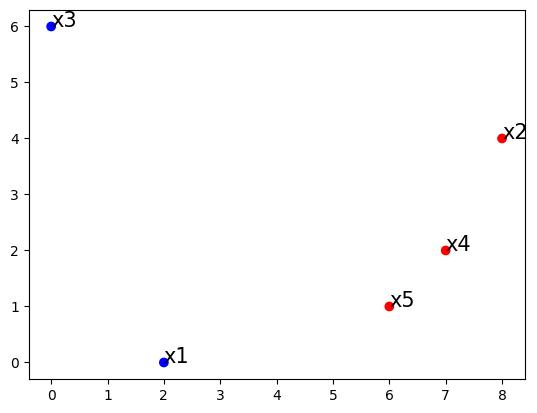

In [5]:
clustering = AgglomerativeClustering(n_clusters=2, linkage="complete").fit(hdata)
plt.scatter(hdata.X, hdata.Y, c=clustering.labels_, cmap="bwr")
for i in range(len(hdata.index)):
    plt.text(hdata.loc[labels[i], "X"], hdata.loc[labels[i], "Y"], '%s' % (str(labels[i])), size=15, zorder=1) 
plt.show()

In [6]:
europeData = pd.read_csv("./europe.txt")

In [7]:
scaler = StandardScaler()
scaler = scaler.fit(europeData)
europe = pd.DataFrame(scaler.transform(europeData), columns=europeData.columns, index=europeData.index)

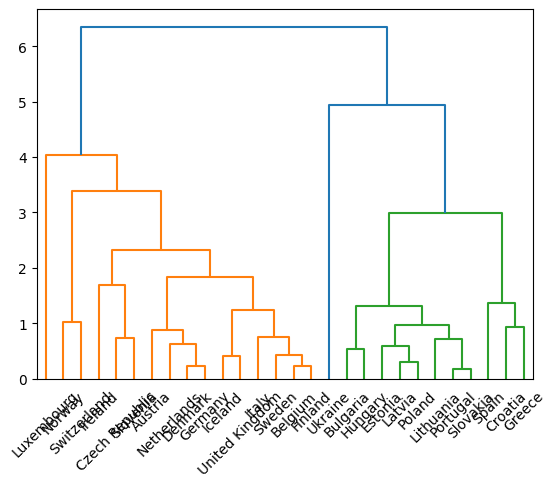

In [8]:
clustering = AgglomerativeClustering(n_clusters=None, linkage="complete", distance_threshold=0).fit(europe)
linkage_matrix = np.column_stack([clustering.children_, clustering.distances_, np.ones(len(europe.index)-1)]).astype(float)
dendrogram(linkage_matrix, labels=europe.index)
plt.show()

In [9]:
slc = []
for i in range(2, 21):
    clustering = AgglomerativeClustering(n_clusters=i, linkage="complete").fit(europe)
    slc.append(silhouette_score(europe, clustering.labels_))

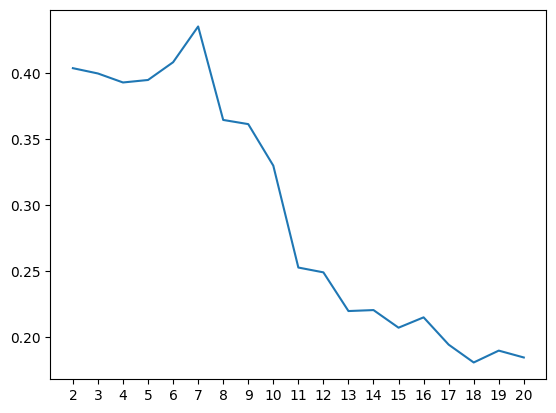

In [10]:
plt.plot(range(2, 21), slc)
plt.xticks(range(2, 21), range(2, 21))
plt.show()

In [11]:
clustering = AgglomerativeClustering(n_clusters=7, linkage="complete").fit(europe)

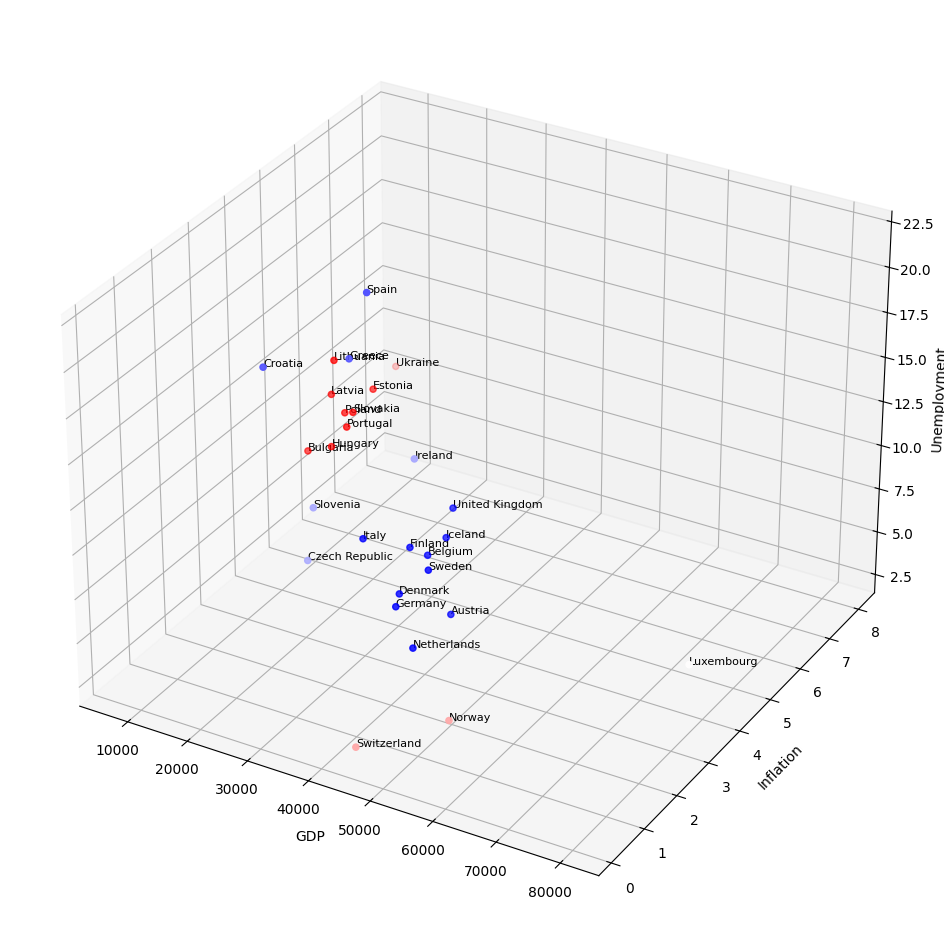

In [12]:
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(projection='3d')
ax.scatter(europeData.GDP, europeData.Inflation, europeData.Unemployment, c=clustering.labels_, cmap="bwr")
for i in range(len(europeData.index)):
    ax.text(europeData.loc[europeData.index[i], "GDP"], europeData.loc[europeData.index[i], "Inflation"], europeData.loc[europeData.index[i], "Unemployment"], '%s' % (str(europeData.index[i])), size=8, zorder=1) 
ax.set_xlabel('GDP')
ax.set_ylabel('Inflation')
ax.set_zlabel('Unemployment')
plt.show()

In [13]:
print(silhouette_score(europe, clustering.labels_))

0.4354272071405595


In [14]:
X = [2, 2, 8, 5, 7, 6, 1, 4]
Y = [10, 5, 4, 8, 5, 4, 2, 9]
labels = ["x1", "x2", "x3", "x4", "x5", "x6", "x7", "x8"]
ddata = pd.DataFrame({"X": X, "Y": Y}, index=labels)

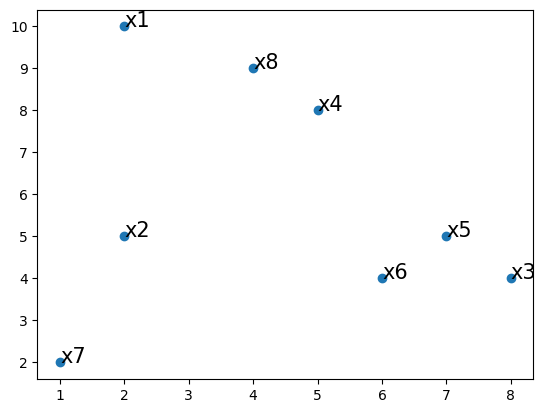

In [15]:
plt.scatter(ddata.X, ddata.Y)
for i in range(len(ddata.index)):
    plt.text(ddata.loc[labels[i], "X"], ddata.loc[labels[i], "Y"], '%s' % (str(labels[i])), size=15, zorder=1) 
plt.show()

In [16]:
clustering = DBSCAN(eps=2, min_samples=2).fit(ddata)

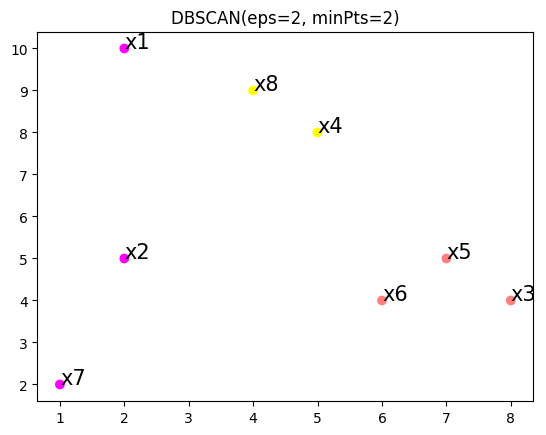

In [17]:
clusters = clustering.labels_
plt.scatter(ddata.X, ddata.Y, c=clusters, cmap="spring")
for i in range(len(ddata.index)):
    plt.text(ddata.loc[labels[i], "X"], ddata.loc[labels[i], "Y"], '%s' % (str(labels[i])), size=15, zorder=1) 
plt.title("DBSCAN(eps=2, minPts=2)")
plt.show()

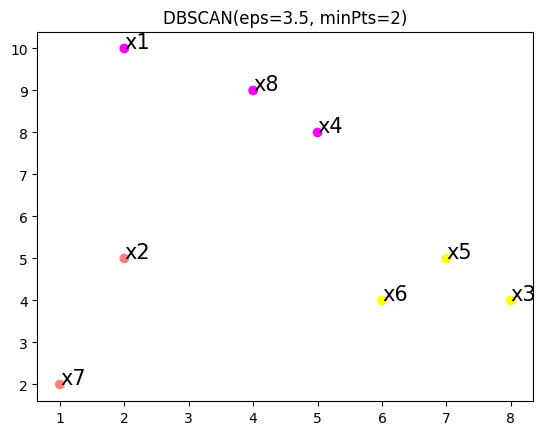

In [18]:
clustering = DBSCAN(eps=3.5, min_samples=2).fit(ddata)
clusters = clustering.labels_
plt.scatter(ddata.X, ddata.Y, c=clusters, cmap="spring")
for i in range(len(ddata.index)):
    plt.text(ddata.loc[labels[i], "X"], ddata.loc[labels[i], "Y"], '%s' % (str(labels[i])), size=15, zorder=1) 
plt.title("DBSCAN(eps=3.5, minPts=2)")
plt.show()

In [19]:
mdata = pd.read_csv("./mdata.txt")

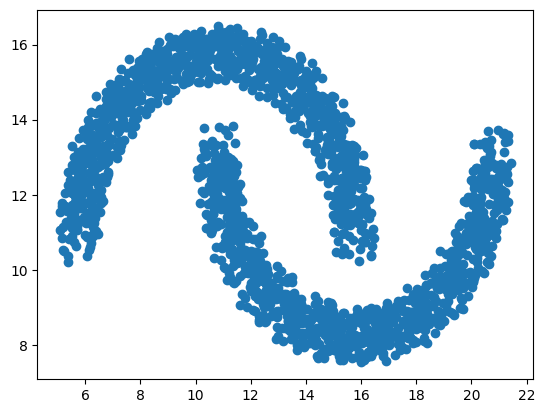

In [20]:
plt.scatter(mdata.X, mdata.Y, marker="o")
plt.show()

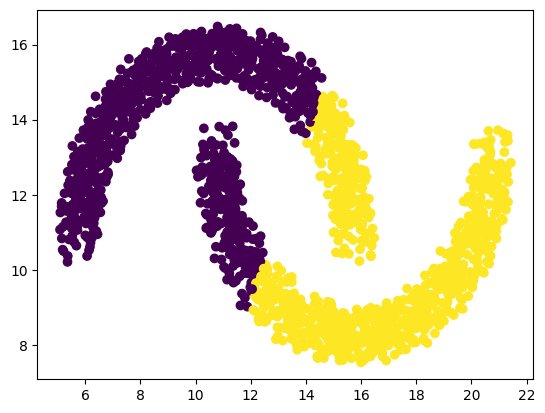

In [21]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=0).fit(mdata)
plt.scatter(mdata.X, mdata.Y, c=kmeans.labels_)
plt.show()

In [22]:
from sklearn.neighbors import NearestNeighbors
nbrs = NearestNeighbors(n_neighbors=10).fit(mdata)
distances, indices = nbrs.kneighbors(mdata)

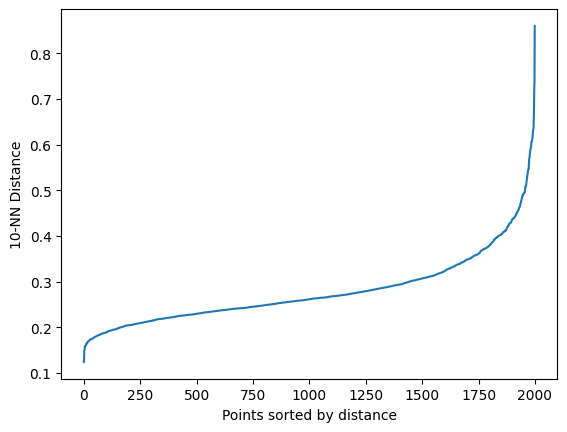

In [23]:
distanceDec = sorted(distances[:, 9])
plt.plot(distanceDec)
plt.ylabel("10-NN Distance")
plt.xlabel("Points sorted by distance")
plt.show()

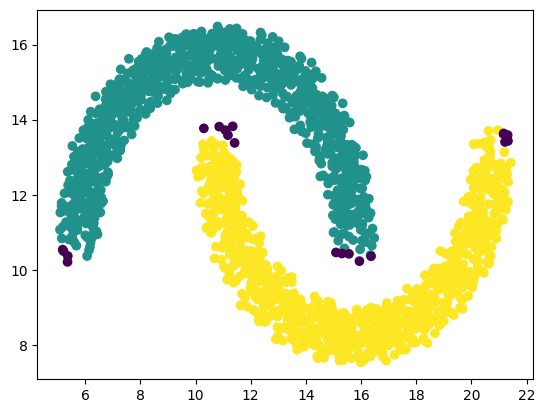

In [24]:
clustering = DBSCAN(eps=0.4, min_samples=10).fit(mdata)
plt.scatter(mdata.X, mdata.Y, c=clustering.labels_)
plt.show()